In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("btc_15m_data_2018_to_2025.csv", sep=",")

# Clean column names
df.columns = df.columns.str.strip()

df['Open time'] = pd.to_datetime(df['Open time'])
df['Close time'] = pd.to_datetime(df['Close time'])

df = df.sort_values('Open time').reset_index(drop=True)

for c in ['Open', 'High', 'Low', 'Close']:
    df[c] = pd.to_numeric(df[c], errors='coerce')

df = df[['Open time', 'Open', 'High', 'Low', 'Close', 'Volume']].copy()
df = df.rename(columns={'Open time': 'Date'})

# Date
start_date = pd.Timestamp('2024-12-19')
end_date = pd.Timestamp('2025-12-20')

df = df[(df['Date'] >= start_date) & (df['Date'] <= end_date)].copy()

In [3]:
ATR_PERIOD = 14

high = df['High']
low = df['Low']
close = df['Close']
prev_close = close.shift(1)

tr = pd.concat([
    high - low,
    (high - prev_close).abs(),
    (low - prev_close).abs()
], axis=1).max(axis=1)

df['ATR'] = tr.rolling(ATR_PERIOD).mean()

# Fill NaN values
if pd.isna(df['ATR'].iloc[ATR_PERIOD]):
    df.loc[ATR_PERIOD, 'ATR'] = tr.iloc[:ATR_PERIOD+1].mean()
df['ATR'] = df['ATR'].ffill()

In [4]:
L, R = 3, 3
p1 = np.zeros(len(df), dtype=bool)

for i in range(L, len(df) - R):
    if df['High'].iloc[i] == df['High'].iloc[i-L:i+R+1].max():
        p1[i] = True

df['P1'] = p1

In [5]:
upper_wick = df['High'] - df[['Open', 'Close']].max(axis=1)
df['Exhaustion'] = upper_wick / df['ATR']

In [6]:
LOOKAHEAD = 48
MAX_ALPHA = 5.0

alpha_star = np.full(len(df), np.nan)

for i in np.where(df['P1'])[0]:
    if i + LOOKAHEAD >= len(df):
        continue
    if np.isnan(df['ATR'].iloc[i]):
        continue

    future_low = df['Low'].iloc[i+1:i+LOOKAHEAD+1].min()
    raw_alpha = (df['High'].iloc[i] - future_low) / df['ATR'].iloc[i]
    alpha_star[i] = min(raw_alpha, MAX_ALPHA)

df['alpha_star'] = alpha_star

In [7]:
ALPHA_TRADE = 0.7
SL_ATR = 1.0
TP_ATR = 1.0
HORIZON = 48

results = []
equity = [1.0]

for i in np.where(
    (df['P1']) &
    (df['alpha_star'] >= 1.0) &
    (df['Exhaustion'] >= 0.6)
)[0]:

    if i + HORIZON >= len(df):
        continue

    atr = df['ATR'].iloc[i]
    if np.isnan(atr):
        continue

    P1 = df['High'].iloc[i]

    entry = P1 - ALPHA_TRADE * atr
    stop = entry + SL_ATR * atr
    target = entry - TP_ATR * atr

    trade_open = False

    for j in range(i + 1, i + HORIZON):
        hi = df['High'].iloc[j]
        lo = df['Low'].iloc[j]

        if not trade_open:
            if lo <= entry <= hi:
                trade_open = True
        else:
            if hi >= stop:
                results.append(-1)
                equity.append(equity[-1] - 1)
                break
            if lo <= target:
                results.append(1)
                equity.append(equity[-1] + 1)
                break

In [8]:
results = np.array(results)

total_trades = len(results)
wins = np.sum(results == 1)
losses = np.sum(results == -1)
win_rate = wins / total_trades if total_trades > 0 else 0

print("Total Trades:", total_trades)
print("Wins:", wins)
print("Losses:", losses)
print("Win Rate:", round(win_rate * 100, 2), "%")

Total Trades: 776
Wins: 528
Losses: 248
Win Rate: 68.04 %


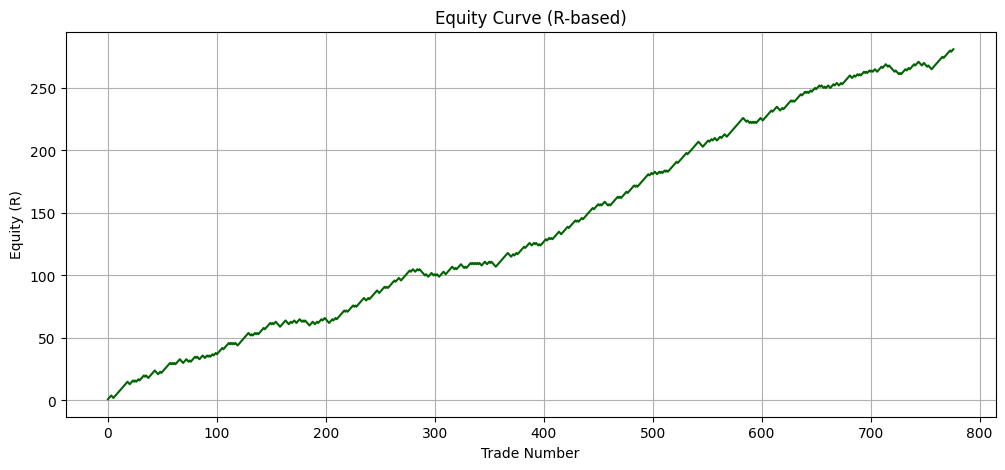

In [9]:
plt.figure(figsize=(12,5))
plt.plot(equity, color='darkgreen')
plt.title("Equity Curve (R-based)")
plt.xlabel("Trade Number")
plt.ylabel("Equity (R)")
plt.grid(True)
plt.show()